# Workout-AI — Model Metrics & Data Visualizations

Evaluates the `ProgressionPredictor` (Ridge + GradientBoosting `VotingRegressor`)
against the seeded workout history in `backend/dev.db`, and visualizes the
underlying training data (weight progression, RPE distribution, HRV/HR signals).

Lives at the repo root and imports the backend package directly, so it can be
run from anywhere with:

```
uv run --project backend jupyter notebook model_metrics.ipynb
```

In [1]:
import sys
from pathlib import Path
import sqlite3
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BACKEND_DIR = Path("backend").resolve()
sys.path.insert(0, str(BACKEND_DIR))

from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from app.ml.model import ProgressionPredictor, _build_sklearn_pipeline, MIN_TRAIN_SAMPLES
from app.ml.features import FEATURE_COLS, build_training_dataset

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

DB_PATH = str(BACKEND_DIR / "dev.db")

## 1. Load data from SQLite

In [2]:
conn = sqlite3.connect(DB_PATH)

sets_df = pd.read_sql_query("""
    SELECT
        e.name            AS exercise_name,
        e.muscle_group    AS muscle_group,
        ws.session_id,
        wss.date          AS date,
        ws.set_order,
        ws.weight,
        ws.reps,
        ws.rpe,
        ws.avg_hr_bpm,
        ws.peak_hr_bpm,
        ws.avg_velocity_mm_s,
        ws.peak_velocity_mm_s,
        ws.velocity_loss_pct,
        ws.source,
        wss.hrv_rmssd_ms,
        wss.resting_hr_bpm
    FROM workout_sets ws
    JOIN exercises        e   ON e.id = ws.exercise_id
    JOIN workout_sessions wss ON wss.id = ws.session_id
    ORDER BY wss.date, ws.session_id, ws.set_order
""", conn, parse_dates=["date"])

records = sets_df.drop(columns=["muscle_group", "avg_velocity_mm_s", "peak_velocity_mm_s",
                                 "velocity_loss_pct", "source"]).assign(
    date=sets_df["date"].dt.strftime("%Y-%m-%d")
).to_dict("records")

print(f"{len(sets_df)} sets across {sets_df['session_id'].nunique()} sessions, "
      f"{sets_df['exercise_name'].nunique()} exercises")
sets_df.head()

720 sets across 72 sessions, 10 exercises


,exercise_name,muscle_group,session_id,date,set_order,weight,reps,rpe,avg_hr_bpm,peak_hr_bpm,avg_velocity_mm_s,peak_velocity_mm_s,velocity_loss_pct,source,hrv_rmssd_ms,resting_hr_bpm
0,Bench Press,Chest,1,2026-05-18,1,60.0,6,6.3,146,165,None,None,None,manual,55.9,60.8
1,Bench Press,Chest,1,2026-05-18,2,60.0,4,7.2,159,167,None,None,None,manual,55.9,60.8
2,Bench Press,Chest,1,2026-05-18,3,60.0,4,7.2,153,170,None,None,None,manual,55.9,60.8
3,Incline Dumbbell Press,Chest,1,2026-05-18,4,27.5,9,6.2,155,174,None,None,None,manual,55.9,60.8
4,Incline Dumbbell Press,Chest,1,2026-05-18,5,27.5,9,7.0,156,168,None,None,None,manual,55.9,60.8


## 2. Dataset overview

In [3]:
sets_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
exercise_name,720,10,Bench Press,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN
muscle_group,720,5,Chest,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session_id,720.0,NaN,NaN,NaN,36.2,1.0,18.75,36.5,54.25,72.0,20.795688
date,720,NaN,NaN,NaN,2026-07-07 09:36:00,2026-05-18 00:00:00,2026-06-16 12:00:00,2026-07-07 00:00:00,2026-07-27 12:00:00,2026-08-28 00:00:00,NaN
set_order,720.0,NaN,NaN,NaN,6.2,1.0,3.0,5.5,9.0,15.0,3.93041
weight,720.0,NaN,NaN,NaN,58.416667,12.5,35.0,56.25,80.625,127.5,30.627876
reps,720.0,NaN,NaN,NaN,8.044444,4.0,5.75,8.0,11.0,13.0,2.86909
rpe,720.0,NaN,NaN,NaN,6.874167,5.8,6.5,6.9,7.2,8.0,0.500152
avg_hr_bpm,720.0,NaN,NaN,NaN,155.666667,142.0,151.0,156.0,160.0,169.0,5.752426
peak_hr_bpm,720.0,NaN,NaN,NaN,169.719444,151.0,165.0,170.0,174.0,189.0,6.803963


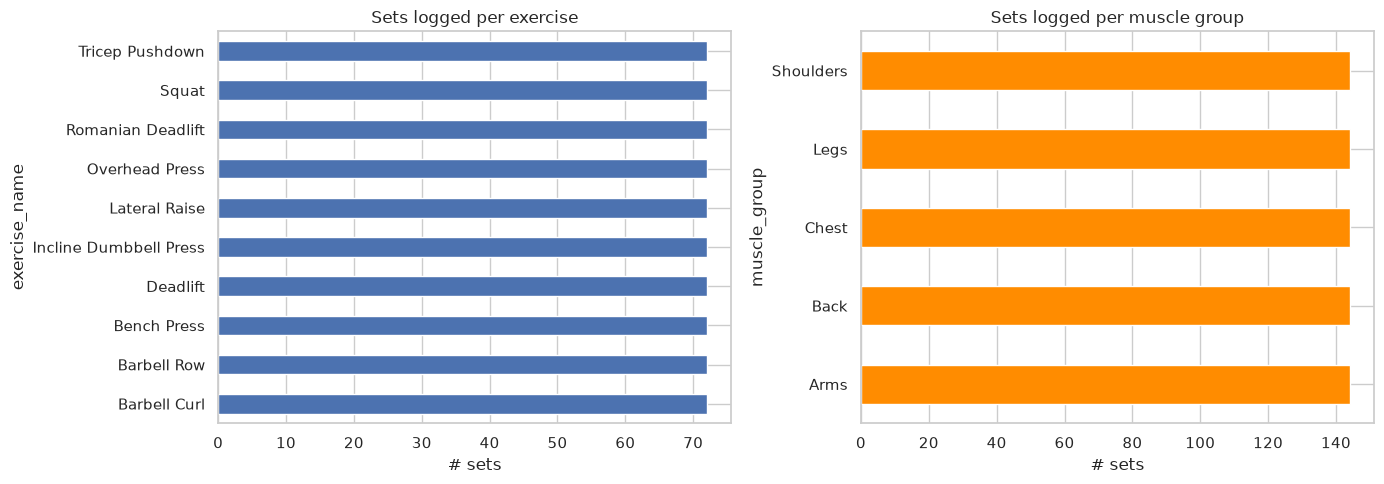

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sets_df.groupby("exercise_name").size().sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Sets logged per exercise")
axes[0].set_xlabel("# sets")

sets_df.groupby("muscle_group").size().sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Sets logged per muscle group")
axes[1].set_xlabel("# sets")

plt.tight_layout()
plt.show()

## 3. Weight progression over time

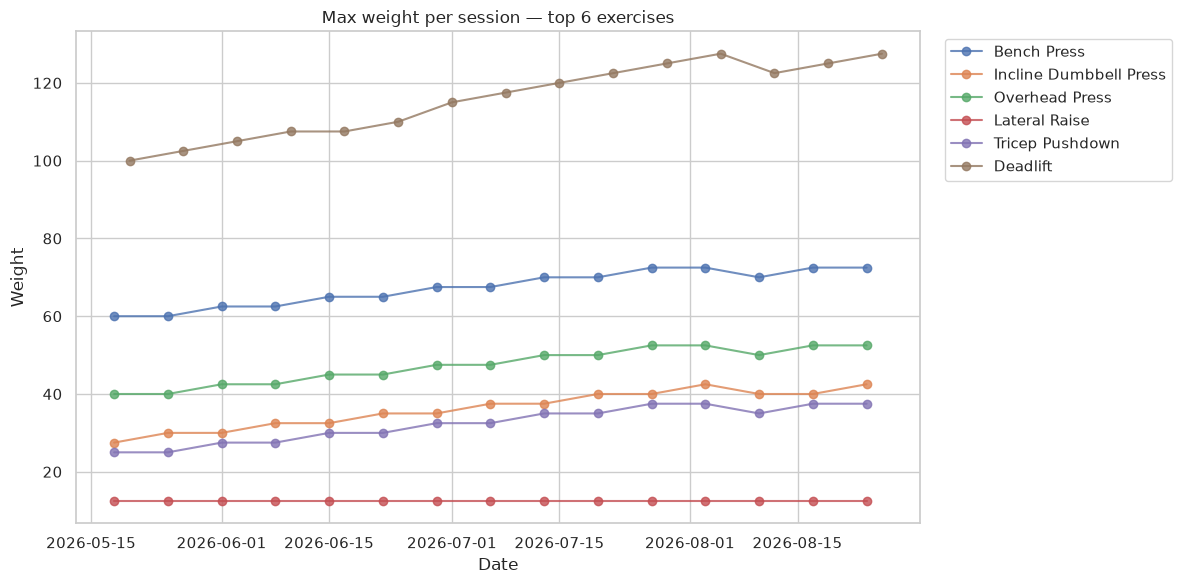

In [5]:
top_exercises = sets_df["exercise_name"].value_counts().head(6).index

fig, ax = plt.subplots(figsize=(12, 6))
for ex in top_exercises:
    sub = sets_df[sets_df["exercise_name"] == ex].groupby("date")["weight"].max().reset_index()
    ax.plot(pd.to_datetime(sub["date"]), sub["weight"], marker="o", label=ex, alpha=0.8)

ax.set_title("Max weight per session — top 6 exercises")
ax.set_xlabel("Date")
ax.set_ylabel("Weight")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 4. RPE distribution & effort signals

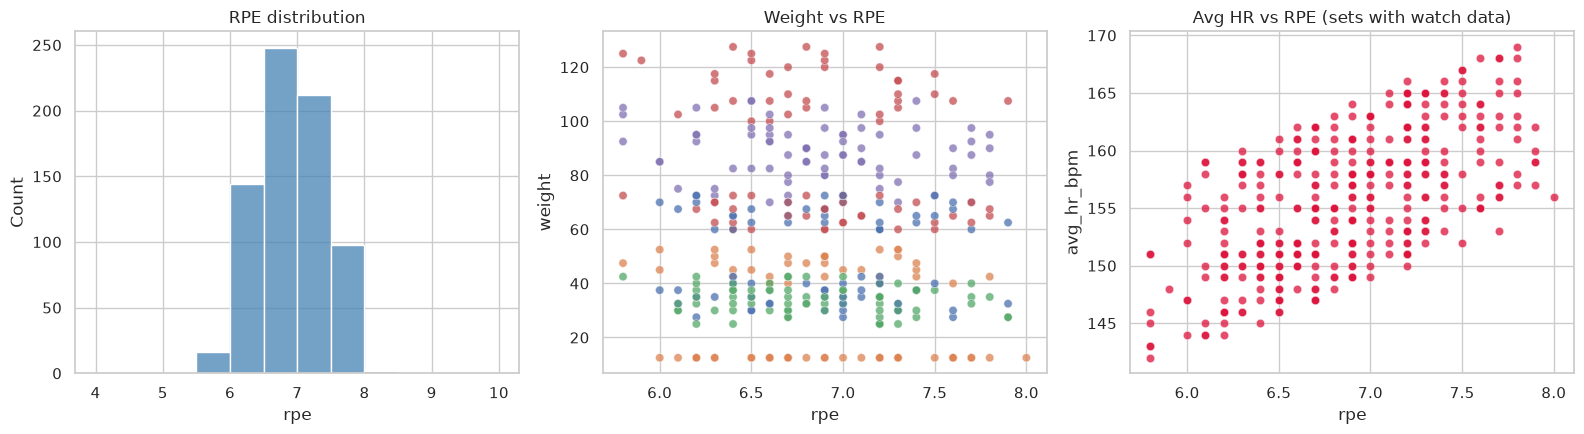

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(sets_df["rpe"].dropna(), bins=np.arange(4, 10.5, 0.5), ax=axes[0], color="steelblue")
axes[0].set_title("RPE distribution")

sns.scatterplot(data=sets_df, x="rpe", y="weight", hue="muscle_group", alpha=0.5, ax=axes[1], legend=False)
axes[1].set_title("Weight vs RPE")

valid_hr = sets_df.dropna(subset=["avg_hr_bpm", "rpe"])
if not valid_hr.empty:
    sns.scatterplot(data=valid_hr, x="rpe", y="avg_hr_bpm", alpha=0.5, ax=axes[2], color="crimson")
axes[2].set_title("Avg HR vs RPE (sets with watch data)")

plt.tight_layout()
plt.show()

## 5. Recovery signals — HRV & resting HR

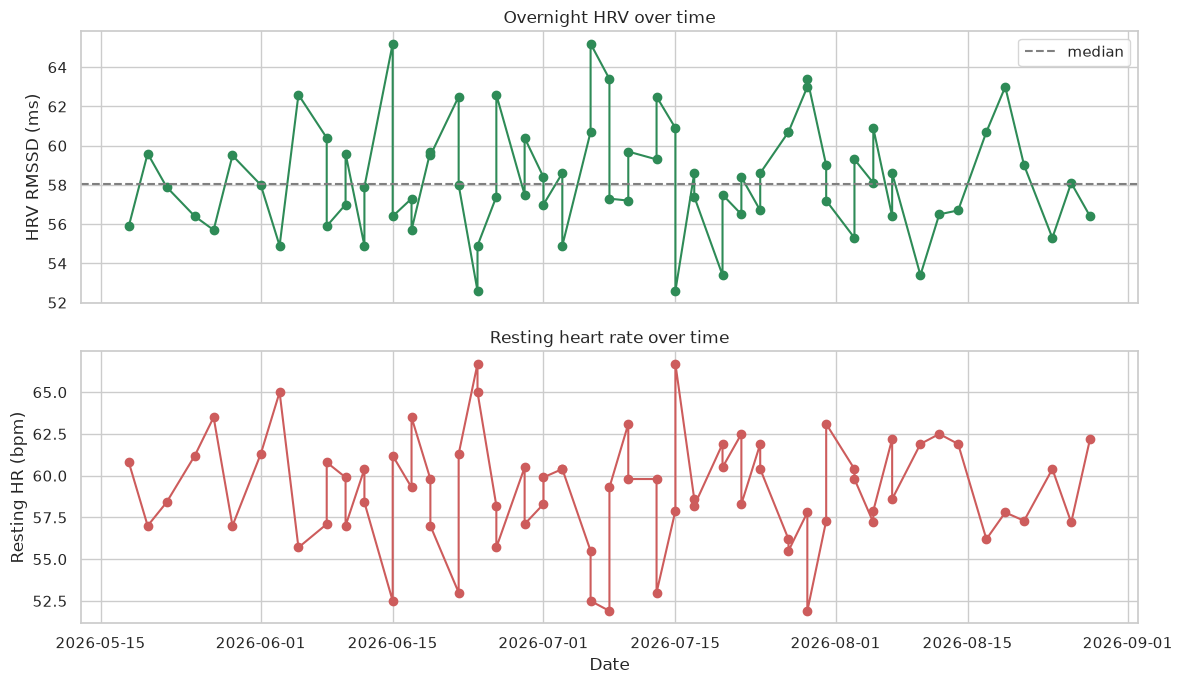

In [7]:
sessions_df = pd.read_sql_query(
    "SELECT id, date, hrv_rmssd_ms, resting_hr_bpm FROM workout_sessions ORDER BY date",
    conn, parse_dates=["date"],
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(sessions_df["date"], sessions_df["hrv_rmssd_ms"], marker="o", color="seagreen")
axes[0].axhline(sessions_df["hrv_rmssd_ms"].median(), color="gray", linestyle="--", label="median")
axes[0].set_ylabel("HRV RMSSD (ms)")
axes[0].set_title("Overnight HRV over time")
axes[0].legend()

axes[1].plot(sessions_df["date"], sessions_df["resting_hr_bpm"], marker="o", color="indianred")
axes[1].set_ylabel("Resting HR (bpm)")
axes[1].set_title("Resting heart rate over time")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

## 6. Feature engineering

Rebuild the exact leave-one-out training set the production model uses
(`build_training_dataset`), so the metrics below match what `just train` produces.

In [8]:
X_dicts, y = build_training_dataset(records)
X_df = pd.DataFrame(X_dicts)[FEATURE_COLS]
y_arr = np.array(y)

print(f"Training rows: {len(y_arr)}  (MIN_TRAIN_SAMPLES = {MIN_TRAIN_SAMPLES})")
X_df.describe().T

Training rows: 710  (MIN_TRAIN_SAMPLES = 10)


,count,mean,std,min,25%,50%,75%,max
last_weight,710.0,58.302817,30.562830,12.5,35.000000,56.250000,80.000000,127.500000
last_reps,710.0,8.040845,2.870947,4.0,5.000000,8.000000,11.000000,13.000000
last_rpe,710.0,6.867887,0.500448,5.8,6.500000,6.900000,7.200000,8.000000
days_since_last,710.0,55.290141,25.942984,3.0,35.000000,56.000000,77.000000,105.000000
sessions_total,710.0,12.591549,6.840058,1.0,7.000000,13.000000,19.000000,24.000000
weight_3s_avg,710.0,57.168633,29.927354,12.5,32.500000,55.781250,80.000000,124.687500
rpe_3s_avg,710.0,6.787348,0.165829,6.1,6.685714,6.787500,6.900000,7.200000
reps_3s_avg,710.0,8.028829,2.766075,4.0,5.200000,7.888889,10.166667,13.000000
target_reps,710.0,8.042254,2.872645,4.0,5.000000,8.000000,11.000000,13.000000
hrv_rmssd_today,710.0,58.493803,2.964161,52.6,56.400000,58.100000,60.700000,65.200000


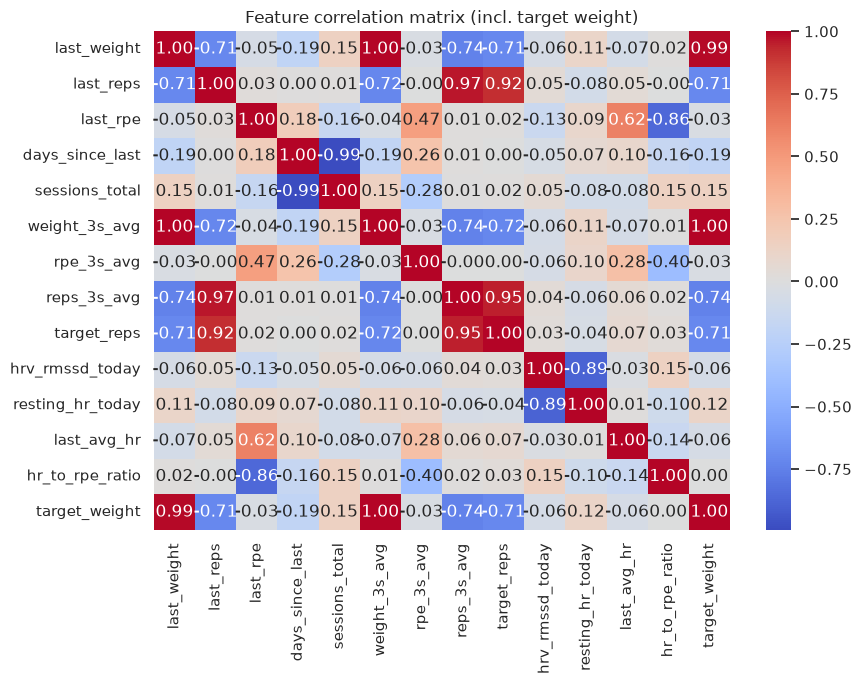

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = X_df.assign(target_weight=y_arr).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Feature correlation matrix (incl. target weight)")
plt.tight_layout()
plt.show()

## 7. Cross-validated model performance

In [10]:
assert len(y_arr) >= MIN_TRAIN_SAMPLES, "Not enough data for ML mode — seed more workouts first."

X = X_df.values
cv_k = min(5, max(3, len(y_arr) // 20))
kf = KFold(n_splits=cv_k, shuffle=True, random_state=42)

rmse_scores = -cross_val_score(_build_sklearn_pipeline(), X, y_arr, scoring="neg_root_mean_squared_error", cv=kf)
mae_scores  = -cross_val_score(_build_sklearn_pipeline(), X, y_arr, scoring="neg_mean_absolute_error", cv=kf)
r2_scores   =  cross_val_score(_build_sklearn_pipeline(), X, y_arr, scoring="r2", cv=kf)

metrics_df = pd.DataFrame({"RMSE": rmse_scores, "MAE": mae_scores, "R2": r2_scores})
metrics_df.index.name = f"fold (k={cv_k})"
metrics_df.loc["mean"] = metrics_df.mean()
metrics_df.loc["std"]  = metrics_df.iloc[:-1].std()
metrics_df.round(3)

,RMSE,MAE,R2
fold (k=5),,,
0,2.445,2.001,0.992
1,3.239,2.570,0.990
2,3.029,2.415,0.990
3,2.854,2.294,0.992
4,2.856,2.307,0.991
mean,2.885,2.317,0.991
std,0.292,0.209,0.001


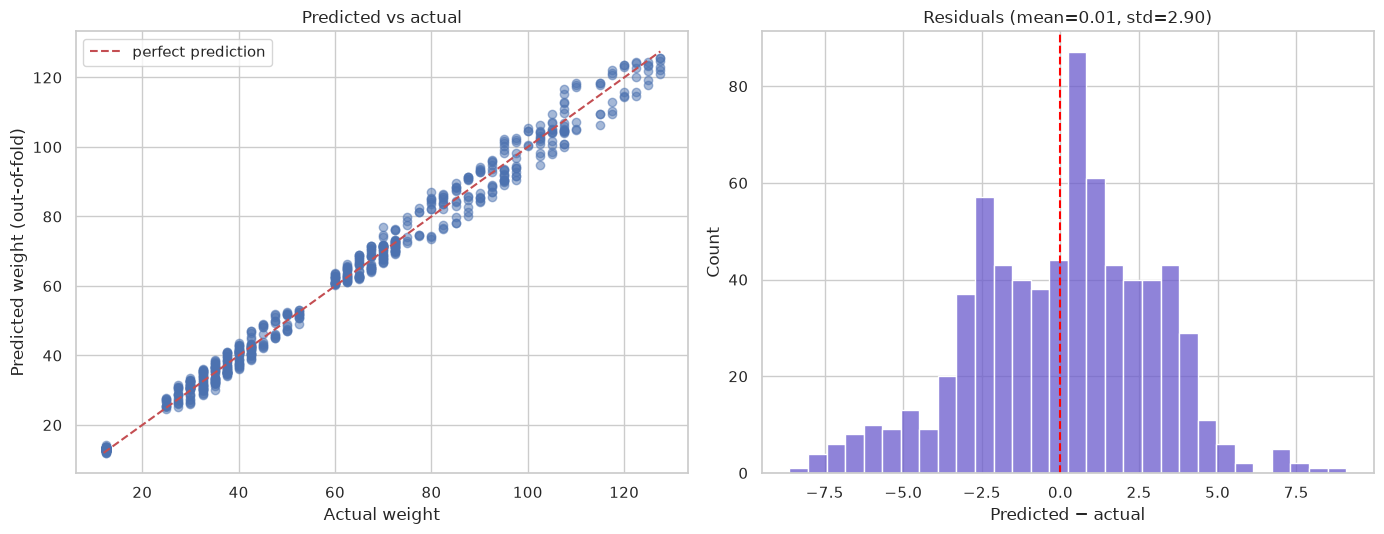

Overall CV RMSE: 2.897
Overall CV MAE:  2.317
Overall CV R2:   0.991


In [11]:
y_pred_cv = cross_val_predict(_build_sklearn_pipeline(), X, y_arr, cv=kf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(y_arr, y_pred_cv, alpha=0.5)
lims = [min(y_arr.min(), y_pred_cv.min()), max(y_arr.max(), y_pred_cv.max())]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual weight")
axes[0].set_ylabel("Predicted weight (out-of-fold)")
axes[0].set_title("Predicted vs actual")
axes[0].legend()

residuals = y_pred_cv - y_arr
sns.histplot(residuals, bins=30, ax=axes[1], color="slateblue")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title(f"Residuals (mean={residuals.mean():.2f}, std={residuals.std():.2f})")
axes[1].set_xlabel("Predicted − actual")

plt.tight_layout()
plt.show()

print(f"Overall CV RMSE: {math.sqrt(mean_squared_error(y_arr, y_pred_cv)):.3f}")
print(f"Overall CV MAE:  {mean_absolute_error(y_arr, y_pred_cv):.3f}")
print(f"Overall CV R2:   {r2_score(y_arr, y_pred_cv):.3f}")

## 8. Feature importance (GradientBoosting sub-model)

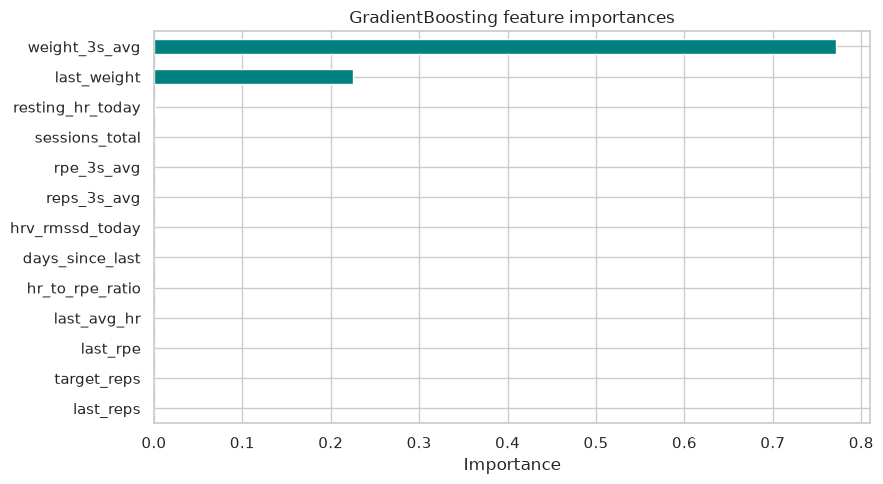

In [12]:
full_pipeline = _build_sklearn_pipeline()
full_pipeline.fit(X, y_arr)
gbr = full_pipeline.named_steps["model"].estimators_[1]  # ("gbr", GradientBoostingRegressor)

importances = pd.Series(gbr.feature_importances_, index=FEATURE_COLS).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
importances.plot.barh(ax=ax, color="teal")
ax.set_title("GradientBoosting feature importances")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 9. Ridge vs GradientBoosting — sub-model agreement

The production confidence score is derived from how much the two sub-estimators
in the `VotingRegressor` disagree, normalised by CV RMSE (see
`ProgressionPredictor._ensemble_confidence`).

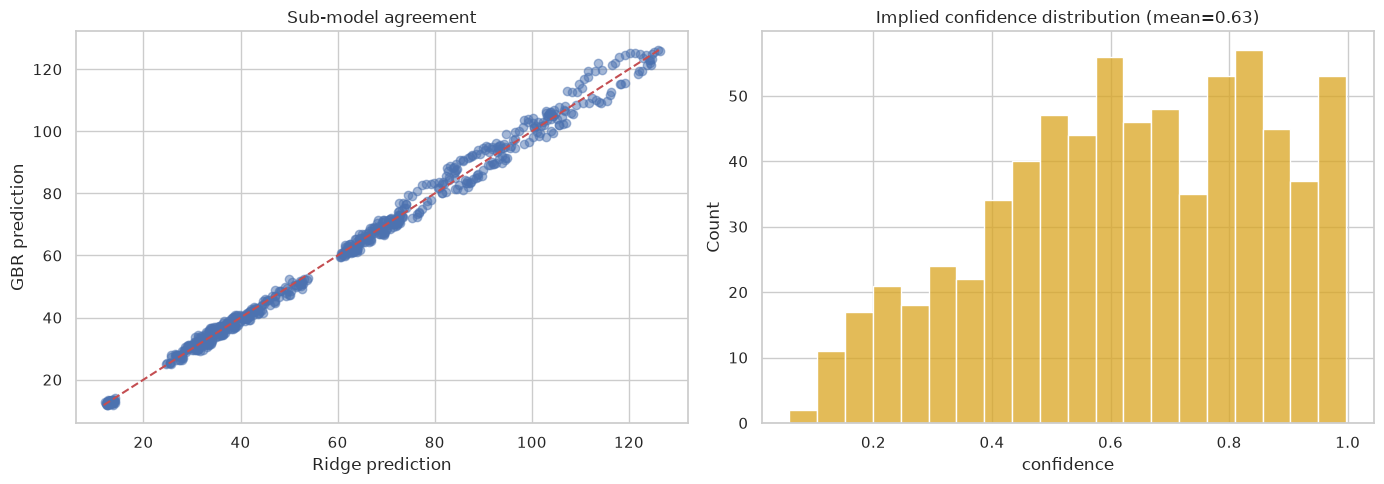

In [13]:
ridge_pred = full_pipeline.named_steps["model"].estimators_[0].predict(
    full_pipeline.named_steps["scale"].transform(full_pipeline.named_steps["impute"].transform(X))
)
gbr_pred = full_pipeline.named_steps["model"].estimators_[1].predict(
    full_pipeline.named_steps["scale"].transform(full_pipeline.named_steps["impute"].transform(X))
)

cv_rmse = metrics_df.loc["mean", "RMSE"]
disagreement = np.abs(ridge_pred - gbr_pred)
confidence = np.exp(-disagreement / cv_rmse)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(ridge_pred, gbr_pred, alpha=0.5)
lims = [min(ridge_pred.min(), gbr_pred.min()), max(ridge_pred.max(), gbr_pred.max())]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Ridge prediction")
axes[0].set_ylabel("GBR prediction")
axes[0].set_title("Sub-model agreement")

sns.histplot(confidence, bins=20, ax=axes[1], color="goldenrod")
axes[1].set_title(f"Implied confidence distribution (mean={confidence.mean():.2f})")
axes[1].set_xlabel("confidence")

plt.tight_layout()
plt.show()

## 10. Per-exercise error breakdown

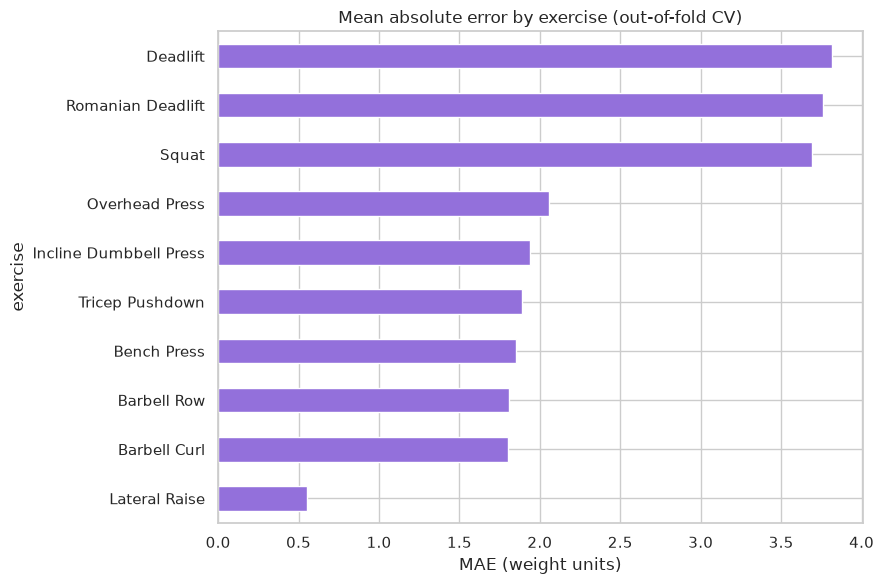

,mean,count
exercise,,
Lateral Raise,0.55,71
Barbell Curl,1.80,71
Barbell Row,1.81,71
Bench Press,1.85,71
Tricep Pushdown,1.89,71
Incline Dumbbell Press,1.94,71
Overhead Press,2.06,71
Squat,3.69,71
Romanian Deadlift,3.76,71


In [14]:
ex_names = [str(r.get("exercise_name") or "") for r in records if r.get("weight") is not None]
# align exercise names to X/y rows: build_training_dataset iterates per-exercise in insertion
# order, so recompute alongside to keep indices in sync.
from app.ml.features import build_training_dataset as _btd

by_exercise = {}
for r in records:
    ex = str(r.get("exercise_name") or "")
    if ex:
        by_exercise.setdefault(ex, []).append(r)

row_exercise = []
for ex, recs in by_exercise.items():
    recs_sorted = sorted(recs, key=lambda r: (str(r.get("date") or ""), int(r.get("set_order") or 0)))
    for i, rec in enumerate(recs_sorted):
        if rec.get("weight") is None or i == 0:
            continue
        row_exercise.append(ex)

err_df = pd.DataFrame({"exercise": row_exercise, "actual": y_arr, "predicted": y_pred_cv})
err_df["abs_error"] = (err_df["predicted"] - err_df["actual"]).abs()

per_ex = err_df.groupby("exercise")["abs_error"].agg(["mean", "count"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 6))
per_ex["mean"].plot.barh(ax=ax, color="mediumpurple")
ax.set_title("Mean absolute error by exercise (out-of-fold CV)")
ax.set_xlabel("MAE (weight units)")
plt.tight_layout()
plt.show()

per_ex.round(2)

## 11. Summary

Quick reference of the headline numbers computed above.

In [15]:
summary = {
    "training_rows": len(y_arr),
    "cv_folds": cv_k,
    "cv_rmse": round(metrics_df.loc["mean", "RMSE"], 3),
    "cv_mae": round(metrics_df.loc["mean", "MAE"], 3),
    "cv_r2": round(metrics_df.loc["mean", "R2"], 3),
    "mean_confidence": round(float(confidence.mean()), 3),
}
pd.Series(summary)

training_rows      710.000
cv_folds             5.000
cv_rmse              2.885
cv_mae               2.317
cv_r2                0.991
mean_confidence      0.629
dtype: float64